In [2]:
import pandas as pd
import numpy as np
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Health_Related_Headlines_Dataset.csv"

df = pd.read_csv(url)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

# Combine headlines and teasers for text analysis
df["text"] = (
    df["Headlines"].fillna("").astype(str) + " " +
    df["Teaser"].fillna("").astype(str)
)

# Initialize stopwords and lemmatizer
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()

    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return cleaned_tokens

# Tokenization, stop-word removal and lemmatization
df["cleaned_tokens"] = df["text"].apply(clean_text)

# Convert tokens back into text
df["cleaned_text"] = df["cleaned_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Remove empty documents
df = df[df["cleaned_text"].str.strip() != ""].copy()

print("\nCleaned text samples:")
print(df[["text", "cleaned_text"]].head())


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


First five rows:
               Date                                             Source  \
0    January, 1970                            Medscape Special Reports   
1    January, 1970                               Medscape Medical News   
2      April, 1997   Medscape Psychiatry & Mental Health eJournal [TM]   
3   November, 1997   Medscape Psychiatry & Mental Health eJournal [TM]   
4      March, 2000                               Medscape Medical News   

                                           Headlines  \
0  Special Report: Adult Vaccines -- New ACIP Rec...   
1  Combined Internet and Telephone Intervention M...   
2  Link Between Parental Alcoholism and Childhood...   
3  Methadone Dose in the Treatment of Opiate Depe...   
4  Magnet Treatment Had No Beneficial Effect on P...   

                                              Teaser  \
0  New recommendations for already approved vacci...   
1  In a randomized trial, combined Internet and t...   
2  It is proposed that depressed 

In [3]:
# Combine all cleaned tokens
all_words = [
    word
    for tokens in df["cleaned_tokens"]
    for word in tokens
]

word_freq = Counter(all_words)

# Display the 20 most frequent words
print("Top 20 frequent words:")
print(word_freq.most_common(20))


Top 20 frequent words:
[('patient', 12973), ('new', 7995), ('risk', 7630), ('study', 6930), ('drug', 6566), ('treatment', 5779), ('cancer', 5628), ('pain', 5613), ('use', 4993), ('may', 4854), ('disease', 4114), ('vaccine', 3499), ('therapy', 3479), ('trial', 3087), ('care', 2856), ('fda', 2794), ('opioid', 2751), ('year', 2685), ('health', 2627), ('child', 2562)]


In [4]:
# Combine all cleaned tokens
all_words = [
    word
    for tokens in df["cleaned_tokens"]
    for word in tokens
]

word_freq = Counter(all_words)

# Display the 20 most frequent words
print("Top 20 frequent words:")
print(word_freq.most_common(20))


Top 20 frequent words:
[('patient', 12973), ('new', 7995), ('risk', 7630), ('study', 6930), ('drug', 6566), ('treatment', 5779), ('cancer', 5628), ('pain', 5613), ('use', 4993), ('may', 4854), ('disease', 4114), ('vaccine', 3499), ('therapy', 3479), ('trial', 3087), ('care', 2856), ('fda', 2794), ('opioid', 2751), ('year', 2685), ('health', 2627), ('child', 2562)]


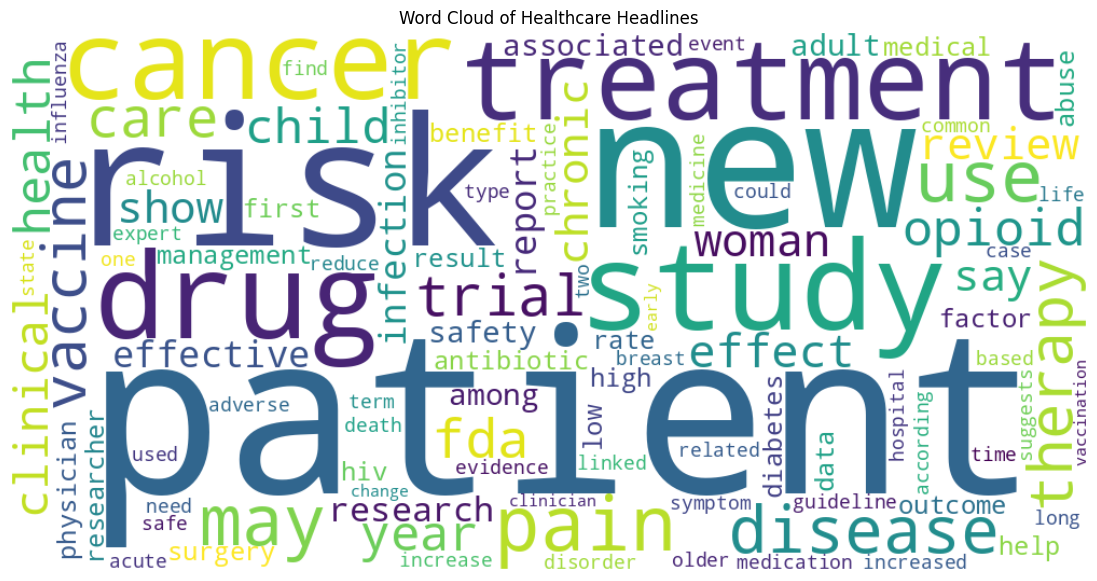

In [5]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate_from_frequencies(word_freq)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Healthcare Headlines")
plt.show()


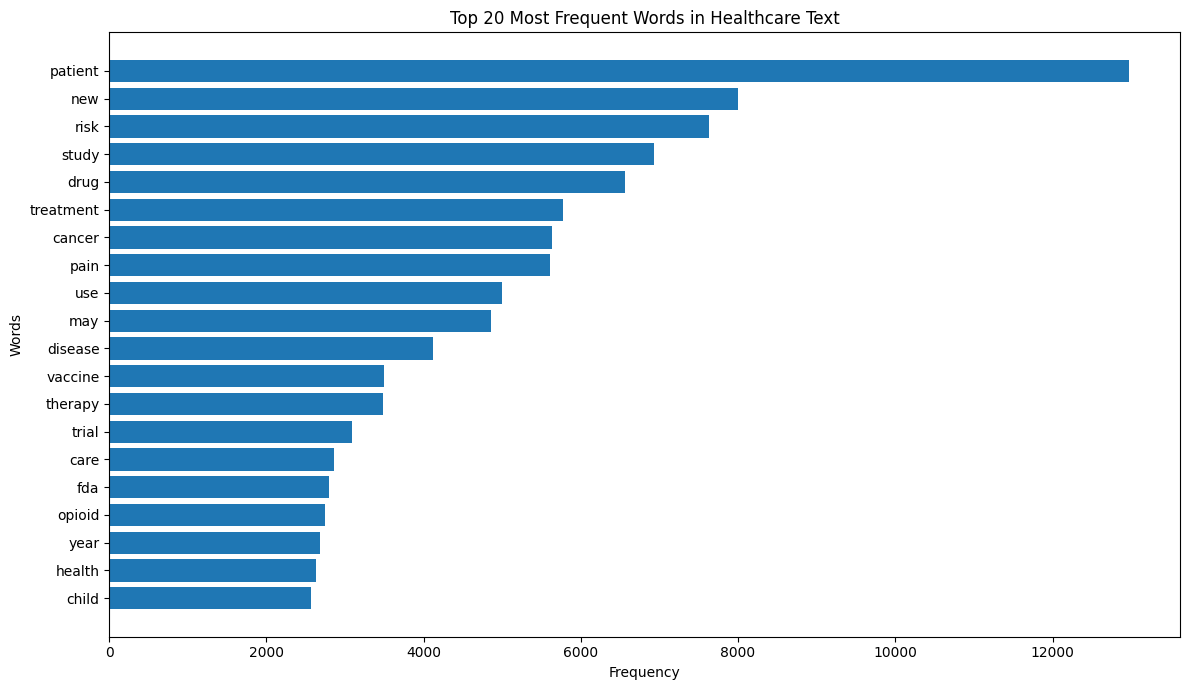

In [6]:
top_words = word_freq.most_common(20)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 7))
plt.barh(words[::-1], frequencies[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words in Healthcare Text")
plt.tight_layout()
plt.show()


In [7]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert cleaned text into a document-term matrix
vectorizer = CountVectorizer(
    max_df=0.85,
    min_df=10,
    max_features=2000
)

dtm = vectorizer.fit_transform(df["cleaned_text"])

print("Document-term matrix shape:", dtm.shape)

# Train LDA model
num_topics = 7

lda_model = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(dtm)

# Display top 5 words for each topic
feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")


Document-term matrix shape: (39405, 2000)
Topic 1: vaccine, child, infection, influenza, vaccination
Topic 2: risk, study, use, may, patient
Topic 3: treatment, patient, therapy, trial, new
Topic 4: pain, opioid, chronic, use, abuse
Topic 5: patient, care, surgery, hospital, outcome
Topic 6: cancer, woman, may, breast, child
Topic 7: drug, new, fda, hiv, health


In [8]:
import pyLDAvis
import pyLDAvis.lda_model

# Prepare interactive LDA visualization
vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa"
)

pyLDAvis.display(vis)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
